<h1>CME538 - Introduction to Data Science</h1><h2>Lecture 7.2 - Classification II</h2><p>Lecture 7.1 fitted probabilities. This lecture turns them into decisions, counts the different mistakes, and chooses metrics to match a practical purpose. Central question: Which decisions should we make from a probability, and how should we judge them?</p><p>You will count classification errors, choose metrics from a practical decision, compare thresholds, read precision-recall and ROC curves, and interpret decision regions.</p><h3>Lecture Structure</h3><ol><li><a href="#section1">Thresholding</a></li><li><a href="#section2">Evaluating Classifiers</a></li><li><a href="#section3">Visual Metrics</a></li><li><a href="#section4">Decision Boundaries</a></li><li><a href="#section5">Multiclass Classification</a></li></ol><p><a href="#summary">Lecture summary</a></p><h3>Sources and documentation</h3><p><a href="DATA_SOURCES.md">Data descriptions and attribution</a>. <a href="https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics">Classification metrics</a>. <a href="https://scikit-learn.org/stable/modules/classification_threshold.html">Choosing a decision threshold</a>.</p>

<h2>Setup Notebook</h2><p>Run the prepared cells in order in the course environment. The <a href="requirements.txt">dependency list</a> records the required packages. All examples use local data. Plot layout and display helpers live in <code>utils.py</code>. The methods being taught remain visible.</p>

In [1]:
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, precision_recall_curve, roc_curve, roc_auc_score, average_precision_score)
from sklearn.datasets import load_iris
from sklearn.multiclass import OneVsRestClassifier
import utils

utils = importlib.reload(utils)

RANDOM_STATE = 538
rng = np.random.default_rng(RANDOM_STATE)
utils.configure_plots()

<a id="section1"></a><h2>1. Thresholding</h2><p>Question: How do different thresholds change predictions from the same fitted probabilities?</p>

<h3>1.1 Keep games together</h3><p>We continue the NBA example. Each row describes one team in a completed game. A second row describes its opponent. We split unique games so these related rows remain together. These final statistics support retrospective classification, not a pre-game forecast.</p>

In [2]:
nba = pd.read_csv('nba.csv')
paired = nba.merge(nba, on='GAME_ID', suffixes=('', '_OPP'))
paired = paired.loc[paired.TEAM_ID != paired.TEAM_ID_OPP].copy()
games = pd.DataFrame({
    'GAME_ID': paired.GAME_ID,
    'FG_PCT_DIFF': paired.FG_PCT - paired.FG_PCT_OPP,
    'PF_DIFF': paired.PF - paired.PF_OPP,
    'WON': (paired.WL == 'W').astype(int),
}).reset_index(drop=True)
display(games.head())

,GAME_ID,FG_PCT_DIFF,PF_DIFF,WON
0,21700002,0.053,9,0
1,21700002,-0.053,-9,1
2,21700001,-0.049,-1,0
3,21700001,0.049,1,1
4,21700011,-0.026,-2,0


In [3]:
train_ids, val_ids = train_test_split(games.GAME_ID.unique(),
    test_size=0.25, random_state=RANDOM_STATE)
train = games.loc[games.GAME_ID.isin(train_ids)]
val = games.loc[games.GAME_ID.isin(val_ids)]
assert set(train_ids).isdisjoint(val_ids)
model = LogisticRegression(C=1e6, max_iter=2000)
model.fit(train[['FG_PCT_DIFF']], train.WON)
val_probability = model.predict_proba(val[['FG_PCT_DIFF']])[:, 1]
print("Probability column labels:", model.classes_)

Probability column labels: [0 1]


<h3>1.2 Apply a threshold</h3><p><code>predict_proba</code> returns one column per class in the order recorded by <code>model.classes_</code>. Here the classes are [0, 1], so column 1 contains the probability of a win. <code>predict</code> returns labels using the fitted classifier's default decision rule.</p><p>To choose our own threshold T, predict class 1 when its probability is at least T. Changing T changes the decisions without refitting the model. The validation games will be used to compare thresholds. They are not an untouched final test.</p>

In [4]:
decisions = pd.DataFrame({'Probability': val_probability[:8]})
decisions['Default predict'] = model.predict(val[['FG_PCT_DIFF']].iloc[:8])
for threshold in [0.3, 0.5, 0.7]:
    decisions[f'T = {threshold}'] = (decisions.Probability >= threshold).astype(int)
display(decisions.round(3))

,Probability,Default predict,T = 0.3,T = 0.5,T = 0.7
0,0.288,0,0,0,0
1,0.712,1,1,1,1
2,0.843,1,1,1,1
3,0.157,0,0,0,0
4,0.771,1,1,1,1
5,0.229,0,0,0,0
6,0.301,0,1,0,0
7,0.699,1,1,1,0


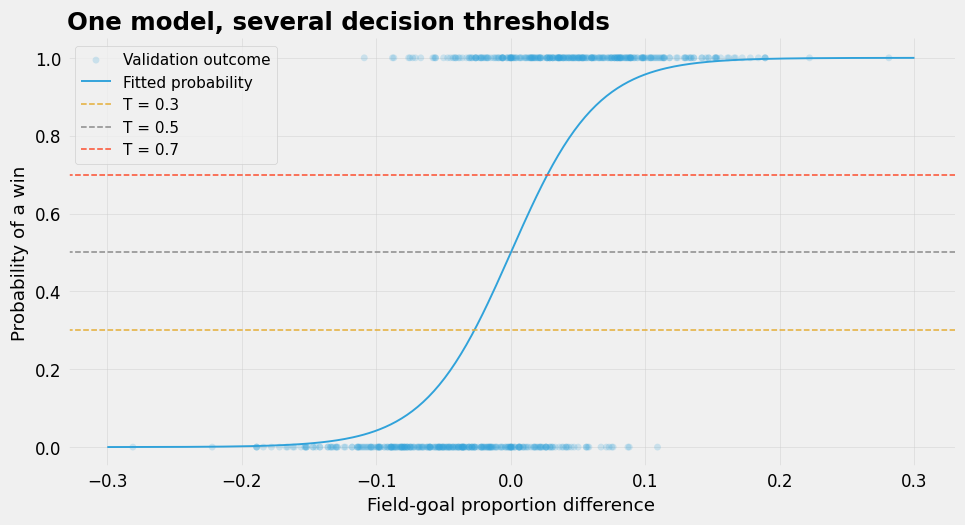

In [5]:
grid = np.linspace(-0.3, 0.3, 300)
grid_probability = model.predict_proba(pd.DataFrame({'FG_PCT_DIFF': grid}))[:, 1]
utils.probability_threshold(val.FG_PCT_DIFF, val.WON, grid, grid_probability)

<p>Takeaway: A probability is a model output. A class prediction also needs a threshold. Lowering the threshold never removes a predicted win. The model stays fixed. Next, compare these decisions with the recorded outcomes and distinguish the different mistakes.</p>

<a id="section2"></a><h2>2. Evaluating Classifiers</h2><p>Question: Which mistakes does an accuracy score hide?</p><p>Evaluation starts with a decision. Define the positive class, count correct decisions and errors, then choose a score to match the consequences. A metric summarizes one part of performance. No single metric describes every practical concern.</p>

<h3>2.1 Define the positive class</h3><p>Our small image example asks whether the image contains a domestic cat. A tiger is not a domestic cat, and a partly hidden domestic cat still counts. The illustrations and assigned scores are a teaching example, not the output of an image model.</p>

<p><img src="classification_animals.png" alt="Six animal images in a two-row grid: domestic cat, tiger, raccoon, husky, hamster, and partly hidden domestic cat." width="900"></p><p>Read left to right: A, B and C are in the top row; D, E and F are in the bottom row.</p>

In [6]:
animals = pd.DataFrame({
    'Image': list('ABCDEF'),
    'Animal': ['Domestic cat', 'Tiger', 'Raccoon', 'Husky', 'Hamster', 'Hidden cat'],
    'Actual': [1, 0, 0, 0, 0, 1],
    'Probability': [0.9, 0.8, 0.7, 0.2, 0.1, 0.4],
})
animals['Predicted'] = (animals.Probability >= 0.5).astype(int)
display(animals)

,Image,Animal,Actual,Probability,Predicted
0,A,Domestic cat,1,0.9,1
1,B,Tiger,0,0.8,1
2,C,Raccoon,0,0.7,1
3,D,Husky,0,0.2,0
4,E,Hamster,0,0.1,0
5,F,Hidden cat,1,0.4,0


<h3>2.2 Count the four outcomes</h3><p>A true positive (TP) is a correctly detected cat. A false positive (FP) is a non-cat labelled cat. A false negative (FN) is a missed cat. A true negative (TN) is a correctly rejected non-cat. Positive means the class we want to find. True means the prediction agrees with the recorded label.</p><p>Rows in the confusion matrix are actual classes and columns are predictions, ordered 0 then 1. Correct decisions occupy the diagonal. Off-diagonal cells count the two types of error. Read the colour bar as a count: darker blue means more observations in a cell, regardless of whether those decisions are correct. In a row-normalized matrix, each actual-class row instead sums to 100%. Always check the legend and denominator.</p>

[[2 2]
 [1 1]]
TN = 2, FP = 2, FN = 1, TP = 1


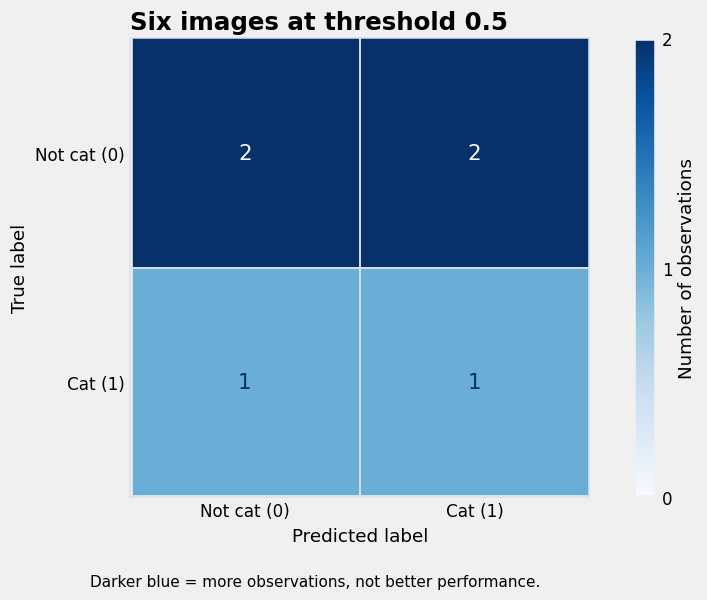

In [7]:
animal_matrix = confusion_matrix(animals.Actual, animals.Predicted, labels=[0, 1])
tn, fp, fn, tp = animal_matrix.ravel()
print(animal_matrix)
print(f'TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')
utils.matrix(animals.Actual, animals.Predicted, 'Six images at threshold 0.5')

<h3>2.3 Choose the denominator</h3><p>The denominator tells us which group the metric describes. The same six decisions produce different answers because each metric asks a different question.</p><table><thead><tr><th>Metric</th><th>Question</th><th>Calculation</th></tr></thead><tbody><tr><td>Accuracy</td><td>What fraction of all decisions is correct?</td><td>(TP + TN) / (TP + TN + FP + FN)</td></tr><tr><td>Precision</td><td>Of the predicted cats, what fraction is cats?</td><td>TP / (TP + FP)</td></tr><tr><td>Recall, also called sensitivity or true-positive rate</td><td>Of all cats present, what fraction did we find?</td><td>TP / (TP + FN)</td></tr><tr><td>F1 score</td><td>How well do precision and recall perform together?</td><td>2 TP / (2 TP + FP + FN)</td></tr></tbody></table><p>These scores range from 0 to 1 when defined. Larger values are better for the particular question. A higher recall alone says nothing about how many false alarms we accept.</p><p>The scikit-learn metric functions take actual labels first and predicted labels second. The next cell calculates the same quantities as the formulas above. <code>pos_label=1</code> identifies cats as the positive class. <code>zero_division=0</code> explicitly reports 0 when a denominator is zero.</p>

In [8]:
scores = pd.Series({
    'Accuracy': accuracy_score(animals.Actual, animals.Predicted),
    'Precision': precision_score(animals.Actual, animals.Predicted, pos_label=1, zero_division=0),
    'Recall': recall_score(animals.Actual, animals.Predicted, pos_label=1, zero_division=0),
    'F1': f1_score(animals.Actual, animals.Predicted, pos_label=1, zero_division=0),
})
display(scores.round(3))

Accuracy     0.500
Precision    0.333
Recall       0.500
F1           0.400
dtype: float64

<p>We correctly label three of six images, so accuracy is 3/6 = 0.50. We call A, B and C cats, but only A is a cat, so precision is 1/3 = 0.33. Two cats are present, A and F, and we find one, so recall is 1/2 = 0.50.</p><p>F1 is the harmonic mean of precision and recall. Here F1 = 2/(2 + 2 + 1) = 0.40. A high F1 requires both precision and recall to be high. F1 treats their roles symmetrically and ignores true negatives. Choose F1 when this summary matches the decision. Class imbalance alone does not make F1 the right objective.</p><p>Precision is undefined when there are no positive predictions. Recall is undefined when there are no actual positives. The interactive displays label these cases undefined. The metric functions above use <code>zero_division=0</code> to report 0 explicitly.</p><h3>2.4 Change the decisions, then recount</h3><p>Keep images A–F and their assigned probabilities. Add three domestic cats and three dogs, labelled G–L, so the slider follows 12 animals. The table below records the same positive class as before: domestic cat = 1. These probabilities are assigned for teaching; we have not trained an image classifier.</p><p>The added photographs come from the later 24-photo grid and retain the same scores there. Their <a href="animal_photos/ATTRIBUTION.md">photograph credits and licences</a> are included beside the notebook.</p>

In [9]:
threshold_animals = utils.animal_threshold_examples(animals)
display(threshold_animals[['Image', 'Animal', 'Actual', 'Cat-feature rating (x)', 'Probability']].round({'Cat-feature rating (x)': 2}))

,Image,Animal,Actual,Cat-feature rating (x),Probability
0,A,Domestic cat,1,7.20,0.90
1,B,Tiger,0,6.39,0.80
2,C,Raccoon,0,5.85,0.70
3,D,Husky,0,3.61,0.20
4,E,Hamster,0,2.80,0.10
5,F,Hidden cat,1,4.59,0.40
6,G,Domestic cat,1,7.59,0.93
7,H,Domestic cat,1,6.52,0.82
8,I,Domestic cat,1,4.80,0.45
9,J,Dog,0,6.05,0.74


<p>The extra images give us five actual cats and seven non-cats. Image G is a cat with probability 0.93, while image I is a cat with probability 0.45. Image J is a dog with probability 0.74. These examples separate the assigned probability from the recorded label: high confidence does not guarantee a correct prediction.</p>

<h4>Follow each animal through the sigmoid</h4>
<p>The input x is a visual cat-feature rating from 0 to 10. Think of an observer rating how cat-like an animal looks: higher ratings represent stronger cat-like appearance. These ratings are invented for this teaching example. They are not extracted from the photos or produced by a trained image classifier. We chose them to retain the probabilities already assigned in the table.</p>
<p>Keep this simple model fixed. A rating of 5 gives a probability of 0.50. Larger ratings give larger probabilities.</p>

$$p(x) = \frac{1}{1 + e^{-(x-5)}}.$$

<p>Each marker is one animal at its recorded label: 1 for a domestic cat and 0 for a non-cat. Its horizontal position is the animal's rating x. The sigmoid curve shows the model's probability at the same rating. The marker and the curve describe different quantities: a cat might have a low predicted probability, or a non-cat might have a high one.</p>
<p>Each thumbnail connects to its animal's marker at 0 or 1. Actual cats appear above the plot and non-cats below the plot. A green TP border means a detected cat, an orange FP border a false alarm, a purple FN border a missed cat, and a blue TN border a correct rejection. The image letter and outcome label identify each thumbnail without relying on colour.</p>
<p>Move T from 0.50 to 0.85, then to 0.30. Predict cat whenever the probability on the curve is at least T. The horizontal dashed line selects the probability threshold. The vertical line marks the corresponding cutoff in the input rating x. Section 4 explains this input cutoff as a decision boundary.</p>
<p>At T = 0.50, the input cutoff is x = 5. Markers at or to its right are predicted cat, including any non-cats at y = 0. Recorded labels, input ratings and the curve stay fixed. Thumbnail borders, TP/FP/FN/TN counts and all three metric equations update together.</p>

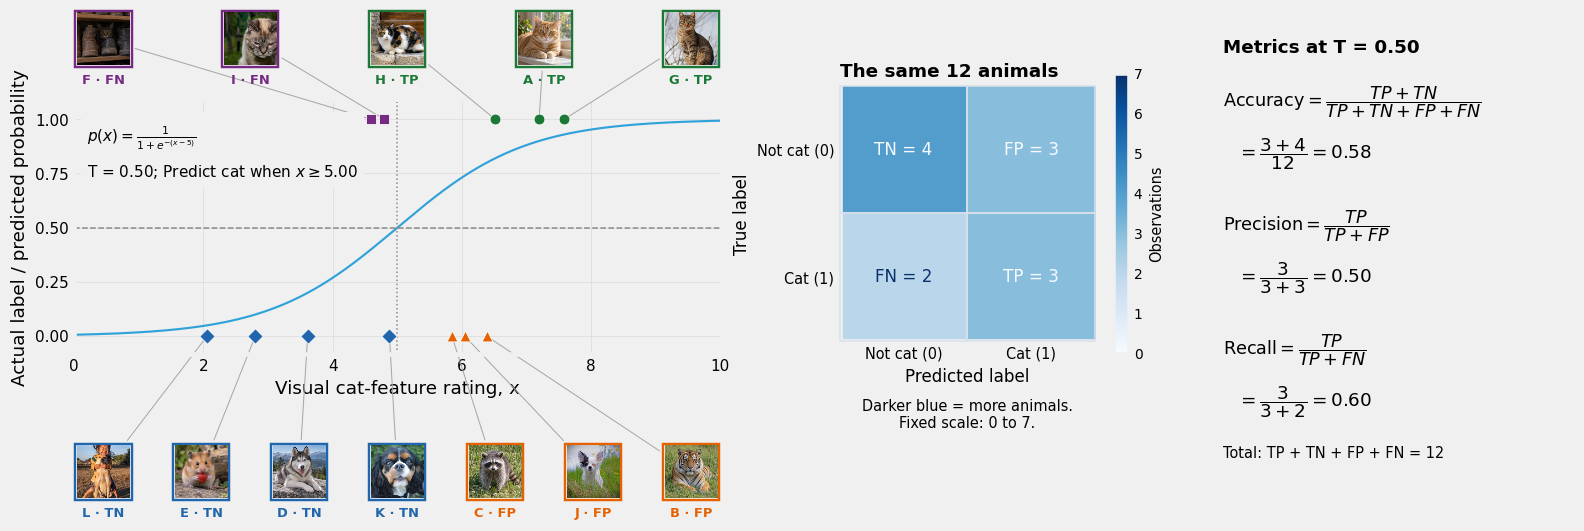

In [10]:
utils.threshold_prediction_plot(start=0.5, animals=threshold_animals)

<p>At T = 0.50, the 12 animals give TP = 3, FP = 3, FN = 2 and TN = 4. Accuracy is 7/12 = 0.58, precision is 3/6 = 0.50, and recall is 3/5 = 0.60. At T = 0.85, only cats A and G are selected: precision becomes 1, but recall falls to 2/5 = 0.40. A shorter list can be more precise while missing more cats.</p><p>At T = 0.30, all five cats are found, along with four non-cats. Recall reaches 1 and precision is 5/9 = 0.56. Watch each thumbnail change category as its probability crosses the threshold. Raising the threshold does not guarantee that precision increases at every step.</p><p>At T = 0, all 12 animals are predicted cat. At T = 1, none of their probabilities reaches the threshold: precision is undefined and recall is 0. The matrix keeps a fixed 0-to-7 colour scale at every threshold. Darker blue means more animals in that cell, not better performance.</p>

<h3>2.5 Read a larger visual example</h3><p>The next grid uses 24 real cat and dog photos with assigned teaching scores and the same definition of the positive class. It includes photos G–L from the slider with unchanged probabilities, plus 18 other photos; it does not include the six illustrations A–F. Move Threshold to change which photos are predicted cat. A photo is predicted cat when its assigned score is at least the threshold. Select All, TP, FP, TN or FN to highlight those outcomes; other photos fade but stay in place. The matching confusion-matrix cell is highlighted too. Counts and metric equations always use all 24 photos, regardless of the highlight selection. Scores and actual labels stay fixed.</p><p>This display uses the same outcome colours as the thumbnail borders: TP is green, FP is orange, FN is purple and TN is blue. The labels identify each category. Colour intensity does not encode the number of images in this display.</p>

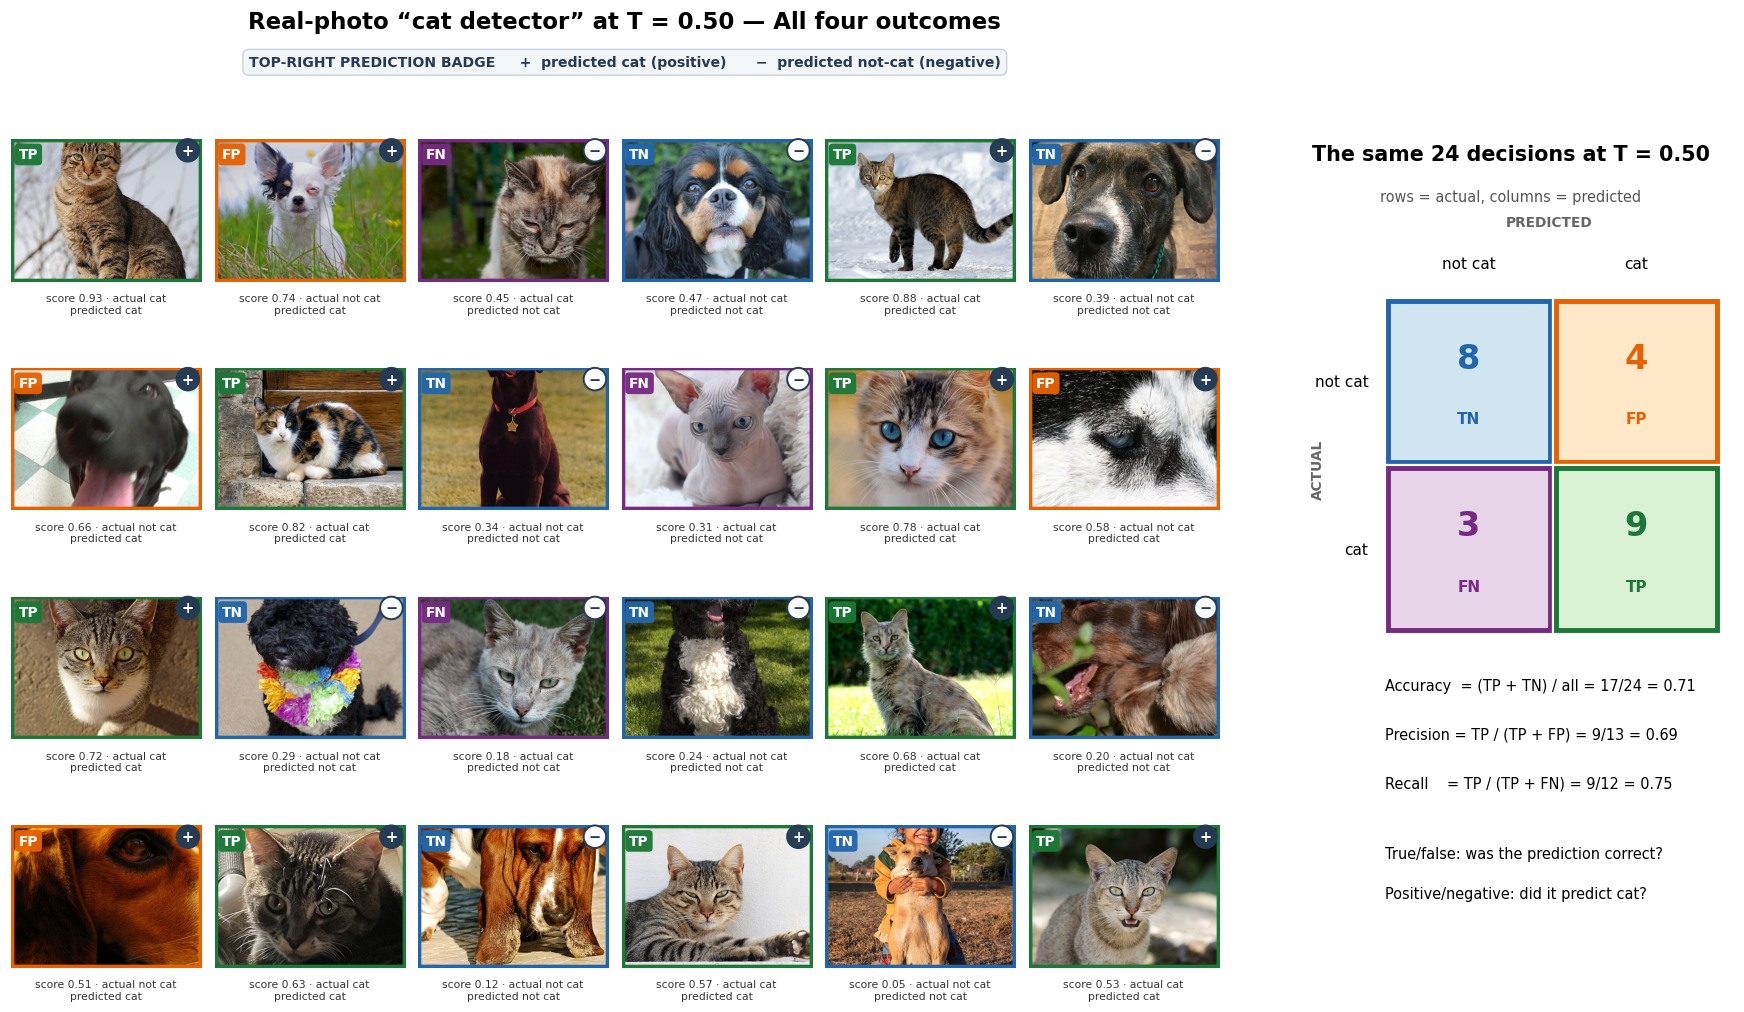

In [11]:
cat_grid = utils.cat_detector_widget(start=0.5)

<h3>2.6 Match the metric to the decision</h3><table><thead><tr><th>Practical question</th><th>Useful metric</th><th>What else to check</th></tr></thead><tbody><tr><td>For a short list of expensive inspection visits, how many alerts identify a defect?</td><td>Precision</td><td>Recall and the number of visits. A precise list might miss many defects.</td></tr><tr><td>For a broad search for relevant books, how many relevant books did we find?</td><td>Recall</td><td>Precision and review effort. Finding everything by selecting everything gives many irrelevant results.</td></tr><tr><td>How often are decisions correct when every error has the same cost?</td><td>Accuracy</td><td>Class frequencies and the performance of a simple baseline.</td></tr><tr><td>We need one summary of precision and recall without counting true negatives.</td><td>F1</td><td>Both component scores and the application costs. F1 does not encode a budget or a required recall.</td></tr></tbody></table><p>The right compromise depends on consequences, available capacity and positive-class frequency. The next illustrative dataset has 50 fraudulent and 950 legitimate transactions. Predicting legitimate for every transaction demonstrates the accuracy problem.</p>

In [12]:
fraud_labels = np.r_[np.ones(50, dtype=int), np.zeros(950, dtype=int)]
always_negative = np.zeros(len(fraud_labels), dtype=int)
print('Accuracy:', accuracy_score(fraud_labels, always_negative))
print('Recall:', recall_score(fraud_labels, always_negative))

Accuracy: 0.95
Recall: 0.0


<p>Takeaway: A 95% accurate classifier misses every positive in this population with 5% positives. Inspect the confusion matrix and choose a metric whose denominator matches the decision. Report the relevant error counts alongside the summary. Next, use curves to compare these scores across many thresholds.</p>

<a id="section3"></a><h2>3. Visual Metrics</h2><p>Question: Which threshold meets a stated validation requirement, and what do PR and ROC curves tell us about the available choices?</p>

<h3>3.1 Compare operating points</h3><p>Return to the NBA validation games. An operating point is the set of decisions and error rates produced by one threshold. We calculate accuracy, precision, recall and F1 for the same fitted probabilities at many thresholds.</p><p>In the next plot the horizontal axis is the decision threshold. The vertical axis is a metric value. Lowering the threshold selects more positives. Recall never decreases as the threshold falls, but precision moves up or down depending on the next selected observations. Changing the threshold does not refit the model.</p><p>The plot omits precision where no positive predictions are made because the denominator is zero. The calculation table still uses the explicit <code>zero_division=0</code> reporting convention.</p>

In [13]:
threshold_rows = []
for threshold in np.linspace(0, 1, 101):
    predicted = (val_probability >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(val.WON, predicted),
        'Precision': precision_score(val.WON, predicted, zero_division=0),
        'Recall': recall_score(val.WON, predicted, zero_division=0),
        'F1': f1_score(val.WON, predicted, zero_division=0),
    })
threshold_scores = pd.DataFrame(threshold_rows)
display(threshold_scores.iloc[[30, 50, 70]].round(3))

,Threshold,Accuracy,Precision,Recall,F1
30,0.3,0.773,0.714,0.909,0.800
50,0.5,0.784,0.789,0.776,0.782
70,0.7,0.773,0.875,0.636,0.737


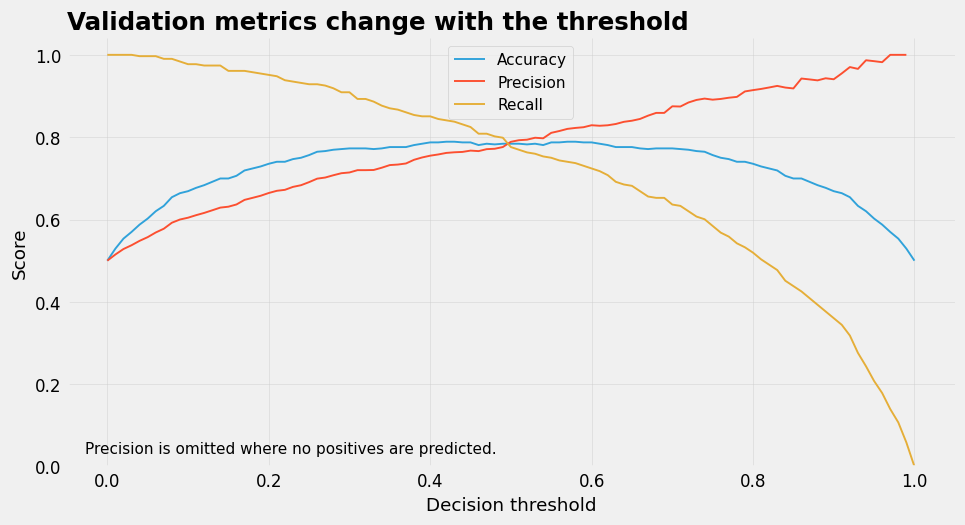

In [14]:
utils.threshold_metrics(threshold_scores, val_probability)

<h3>3.2 State a requirement first</h3><p>Suppose an analyst wants to capture at least 90% of the wins for later review. Among thresholds meeting this validation recall requirement, choose the highest precision. Break ties with the higher threshold. This is an illustrative screening requirement, not a universal basketball objective.</p><p>Fit model parameters using training data. Choose the metric and practical requirement before comparing validation results. Use validation data for the threshold choice, then hold the chosen rule fixed for a final test.</p>

In [15]:
eligible = threshold_scores.loc[threshold_scores.Recall >= 0.9]
chosen = eligible.sort_values(['Precision', 'Threshold'], ascending=False).iloc[0]
display(chosen.round(3))

Threshold    0.300
Accuracy     0.773
Precision    0.714
Recall       0.909
F1           0.800
Name: 30, dtype: float64

<p>The achieved recall is a validation estimate. Selecting this threshold does not guarantee 90% recall on new games. Repeated choices based on the same validation set also risk adapting to its particular observations. Lecture 7.3 reserves a separate test set for a final check after choices are fixed.</p>

<h3>3.3 Read precision-recall and ROC curves</h3><p>A ranking orders observations from the highest predicted probability to the lowest. Sweeping the threshold moves through this ranking. The following two plots show the resulting tradeoffs. Each point represents a threshold applied to the same fitted model. Neither horizontal axis is the threshold.</p><h4>Precision-recall (PR): what fraction of our selections is useful?</h4><p>The horizontal axis is recall, the fraction of actual positives found. The vertical axis is precision, the fraction of selected observations which are positive. Moving toward the top right means finding more positives while keeping the selected set precise. Lowering the threshold moves toward greater recall, although precision need not decrease at every step.</p><p>The dashed line marks prevalence, the fraction of validation observations in the positive class. This is the reference precision for selections unrelated to the labels. PR is especially useful when positives are rare and the quality of an alert list matters. Compare curves on the same target population because prevalence affects precision.</p><h4>Receiver operating characteristic (ROC): how many positives versus negatives do we flag?</h4><p>The horizontal axis is false-positive rate, FP / (FP + TN), the fraction of actual negatives incorrectly selected. The vertical axis is true-positive rate, TP / (TP + FN), which equals recall. Lowering the threshold moves toward larger false-positive and true-positive rates. The top-left corner represents finding all positives with no false positives.</p><p>The diagonal is the expected curve for an uninformative ranking. The area under the ROC curve, ROC AUC, ranges from 0 to 1. An expected value of 0.5 corresponds to random ranking. A value of 1 represents perfect separation. ROC AUC summarizes ranking across thresholds, not the percentage of correct predictions at a chosen threshold.</p><h4>Summarize the curves without losing the decision</h4><p>Average precision (AP) summarizes the PR curve by weighting precision values by the increases in recall as more observations are selected. AP differs from joining PR points with straight lines and calculating trapezoidal area. Larger AP indicates better positive retrieval on the evaluation population. Both AP and ROC AUC summarize rankings. Neither metric specifies which threshold to use. Probability calibration asks whether about 80% of observations assigned probability 0.8 have positive outcomes. AP and ROC AUC do not check calibration.</p><p><a href="https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html">Precision-recall explanation</a>. <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html">Average precision definition</a>. <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html">ROC AUC documentation</a>.</p><p>Pass the positive-class probabilities to <code>precision_recall_curve</code>, <code>roc_curve</code>, <code>average_precision_score</code> and <code>roc_auc_score</code>. Passing thresholded 0/1 predictions would discard the ranking these methods evaluate. The helper below draws the arrays returned by scikit-learn.</p>

Chosen threshold: 0.30
TN = 196, FP = 112, FN = 28, TP = 280


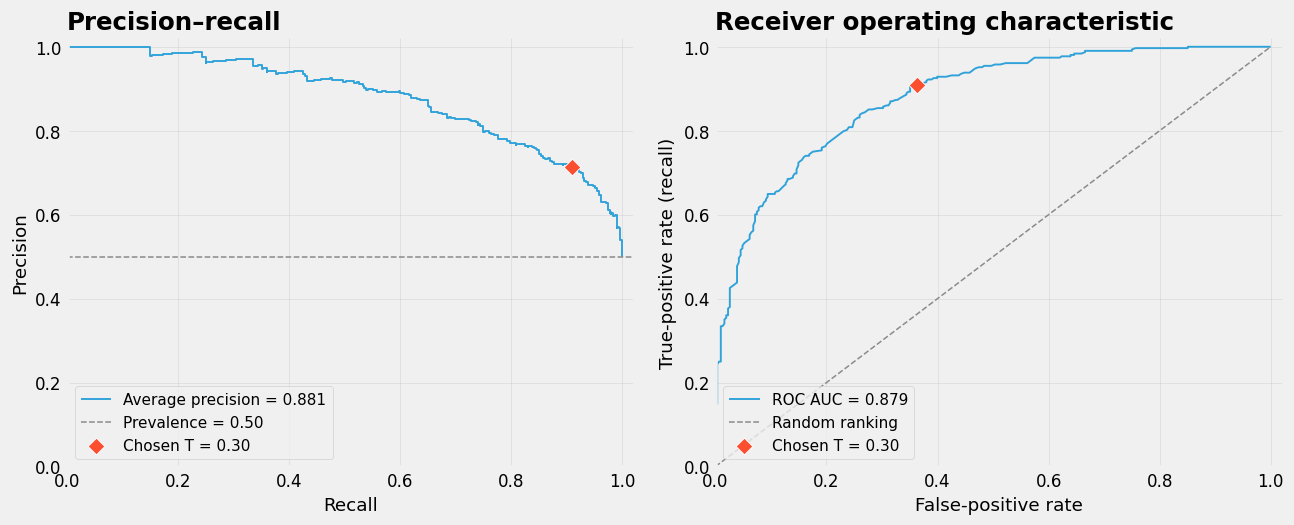

In [16]:
precision, recall, _ = precision_recall_curve(val.WON, val_probability)
fpr, tpr, _ = roc_curve(val.WON, val_probability)
ap = average_precision_score(val.WON, val_probability)
auc = roc_auc_score(val.WON, val_probability)
chosen_prediction = (val_probability >= chosen.Threshold).astype(int)
chosen_tn, chosen_fp, chosen_fn, chosen_tp = confusion_matrix(
    val.WON, chosen_prediction, labels=[0, 1]).ravel()
print(f'Chosen threshold: {chosen.Threshold:.2f}')
print(f'TN = {chosen_tn}, FP = {chosen_fp}, FN = {chosen_fn}, TP = {chosen_tp}')
chosen_point = {
    'Threshold': chosen.Threshold,
    'Precision': chosen.Precision,
    'Recall': chosen.Recall,
    'False-positive rate': chosen_fp / (chosen_fp + chosen_tn),
}
utils.pr_roc(precision, recall, fpr, tpr, ap, auc, val.WON.mean(), chosen_point)

<h3>3.4 Choose the plot for the practical question</h3><p>Use PR to examine the quality and coverage of a positive alert list. Use ROC to compare the fraction of positives found against the fraction of negatives flagged. For example, a 1% false-positive rate sounds small, but with 10,000 negatives this means 100 false alarms. If 100 positives are present and recall is 80%, we find 80 positives. Precision is then 80/(80 + 100) = 0.44. This illustrative example explains why a low false-positive rate alone does not guarantee a precise alert list.</p><p>The red diamond on each curve marks T = 0.30. This rule finds 280 of 308 wins, giving recall 0.909. Its 392 positive predictions include 112 false positives, giving precision 280/392 = 0.714. The false-positive rate is 112/308 = 0.364. Read the relevant region of the curve, inspect the corresponding counts, and check the review workload. Two curves might cross, so a larger overall area need not give better performance at the operating point we need.</p>

<a id="prevalence-comparison"></a><h3>3.5 Class imbalance changes precision</h3>
<p>Question: If positive cases become rarer but the model scores within each class stay the same, which curve changes?</p>
<p>ROC is insensitive to this change in class proportions. Recall divides by the number of actual positives. False-positive rate divides by the number of actual negatives. Changing the relative sizes of the classes leaves those two rates unchanged when the score distributions within each class stay fixed.</p>
<p>Precision uses both classes: TP / (TP + FP). More negatives produce more false positives at the same false-positive rate. The PR curve changes and shows the resulting decrease in the fraction of useful alerts. PR is sensitive to prevalence, not immune to class imbalance.</p>
<h4>Keep the scores fixed and change the class proportions</h4>
<p>We create two synthetic score pools with 1,000 positive and 1,000 negative observations. Higher scores indicate stronger evidence for the positive class. These illustrative scores are not calibrated probabilities. We repeat scores within each class to create illustrative populations of 100,000 cases. For example, 10% positive means 10,000 positives and 90,000 negatives. Every score within a class is repeated equally, so the score distribution within that class stays fixed.</p>
<p>This controlled replication isolates the effect of prevalence. No model is refitted. Repeated rows are not new independent observations or evidence from a larger test set. This demonstration does not resample training data.</p>

In [17]:
prevalence_rng = np.random.default_rng(RANDOM_STATE)
positive_scores = 1 / (1 + np.exp(-prevalence_rng.normal(1, 1, 1000)))
negative_scores = 1 / (1 + np.exp(-prevalence_rng.normal(-1, 1, 1000)))
fixed_threshold = 0.5

<p>First compare populations with 50%, 10% and 1% positives. Calculate the complete curves and metrics at the same threshold, T = 0.50. The slider then changes the positive percentage from 50 down to 1 while keeping the total population fixed.</p><p>The counts explain the change. TP = recall × number of positives; FP = false-positive rate × number of negatives. Precision = TP / (TP + FP). With fewer positives and more negatives, we get fewer true alerts and more false alerts even though the rates within each class stay the same.</p>

In [18]:
prevalence_results = []
prevalence_curve_data = []
for positive_percent in [50, 10, 1]:
    repeated_positives = np.tile(positive_scores, positive_percent)
    repeated_negatives = np.tile(negative_scores, 100 - positive_percent)
    scores = np.concatenate([repeated_positives, repeated_negatives])
    actual = np.concatenate([np.ones(len(repeated_positives), dtype=int),
                             np.zeros(len(repeated_negatives), dtype=int)])
    predicted = (scores >= fixed_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    precision_curve, recall_curve, _ = precision_recall_curve(actual, scores)
    fpr_curve, tpr_curve, _ = roc_curve(actual, scores)
    prevalence_results.append({
        'Positive share': f'{actual.mean():.0%}',
        'ROC AUC': roc_auc_score(actual, scores),
        'AP': average_precision_score(actual, scores),
        'Recall': tp / (tp + fn),
        'FPR': fp / (fp + tn),
        'Precision': tp / (tp + fp),
    })
    prevalence_curve_data.append({
        'prevalence': actual.mean(), 'fpr': fpr_curve, 'tpr': tpr_curve,
        'precision': precision_curve, 'recall': recall_curve,
        'point': {'fpr': fp / (fp + tn), 'recall': tp / (tp + fn),
                  'precision': tp / (tp + fp)},
    })

,ROC AUC,AP,Recall,FPR,Precision
Positive share,,,,,
50%,0.919,0.925,0.837,0.16,0.840
10%,0.919,0.693,0.837,0.16,0.368
1%,0.919,0.346,0.837,0.16,0.050


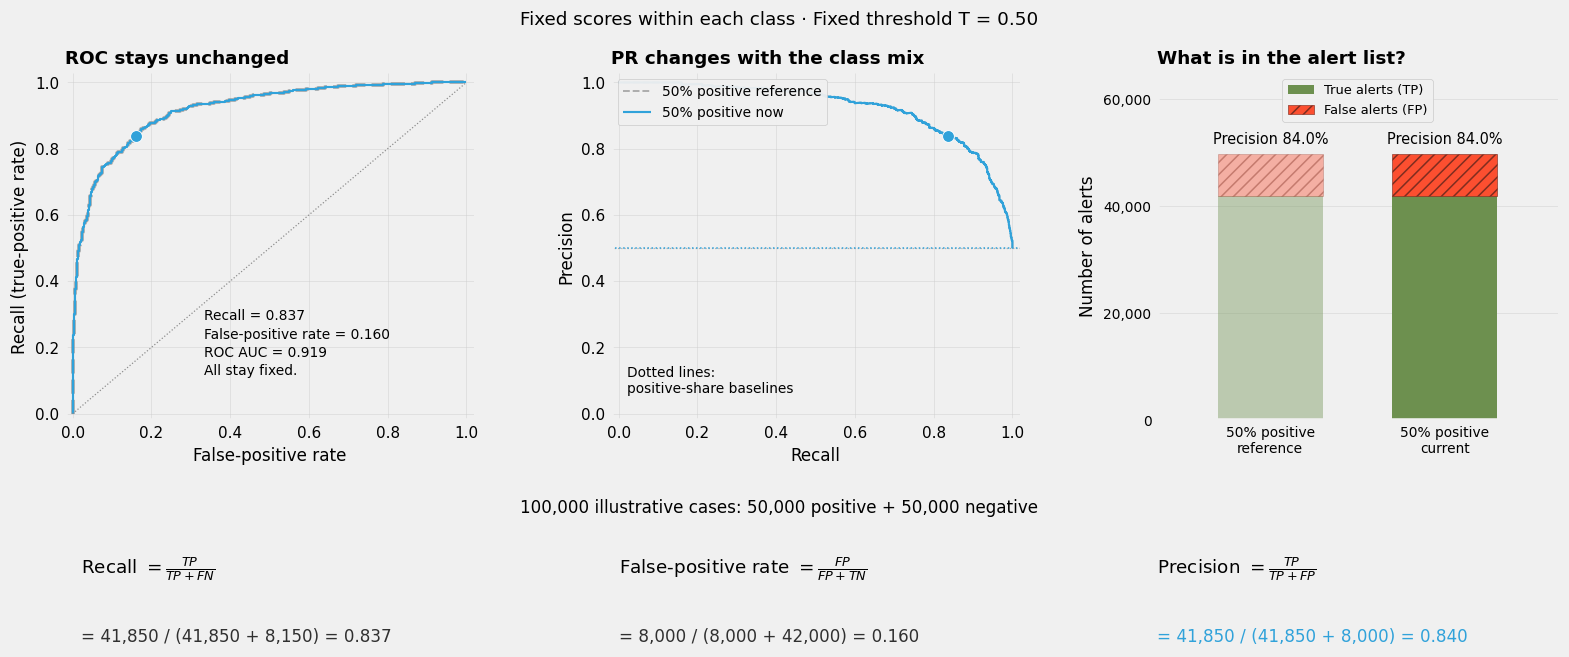

In [19]:
display(pd.DataFrame(prevalence_results).set_index('Positive share').round(3))
prevalence_demo = utils.prevalence_widget(
    prevalence_curve_data[0], roc_auc=prevalence_results[0]['ROC AUC'],
    threshold=fixed_threshold, start=50
)

<h4>Read the two plots together</h4><p>Move the slider from 50% to 10%, then to 1%. The blue ROC curve and its threshold marker stay in the same place: ROC AUC is 0.919, recall is 0.837 and false-positive rate is 0.160 throughout. Each rate divides by the size of its own class.</p><p>The blue PR curve moves below the grey 50% reference. At the same threshold, precision falls from 0.840 to 0.368 to 0.050. At 1% positive, 837 true positives and 15,840 false positives enter the alert list. Only about 5% of alerts are positive, despite a ROC AUC above 0.9. The dotted PR baseline also falls with the positive share. The equations below the plots update with the same counts.</p><p>The stacked bars compare the 50% reference with the current population. Green shows true alerts (TP); hatched red shows false alerts (FP). Lower the positive share and watch the true-alert segment shrink while false alerts grow. Precision is the true-alert fraction of the whole bar. All counts use the same 100,000-case illustrative population.</p><p>ROC describes the ranking and the error rates within each class. PR describes positive retrieval in the evaluated population. Use PR when the fraction of useful alerts matters, and retain ROC when recall versus false-positive rate is the practical question. Compare PR curves on representative populations with the same prevalence, or state the prevalence difference explicitly.</p><p>The ROC overlap depends on keeping the score distribution within each class fixed. The overlap is not guaranteed after retraining or changes to the mix of cases within either class. Fresh random samples also introduce sampling variation. This experiment isolates class proportions alone.</p><p><a href="https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html">Precision-recall curves and the prevalence baseline</a>. <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html">ROC rates and thresholds</a>.</p><p>Takeaway: Choose a threshold using validation data and a stated requirement. Report its confusion matrix and task-relevant metrics. ROC AUC and average precision summarize rankings across thresholds. Neither selects the operating point for us. Changing prevalence alone leaves ROC unchanged under fixed within-class score distributions, while PR shows the change in precision.</p>

<a id="section4"></a><h2>4. Decision Boundaries</h2><p>Question: What does a threshold look like in feature space?</p>

<h3>4.1 One feature</h3><p>The animal slider showed an input cutoff beside the probability threshold. The slides now give this cutoff a name: decision boundary. For the fixed probability model used in the animal slider, and for 0 &lt; T &lt; 1:</p>

$$p(x) \geq T \quad \Longleftrightarrow \quad x \geq 5 + \ln\!\left(\frac{T}{1-T}\right).$$

<p>At T = 0.50, the animal rating boundary is x = 5. Raising T moves this boundary to the right, so fewer animals receive a cat prediction.</p>
<h4>Return to the NBA model</h4><p>The slides illustrated T = 0.3. Here we start at T = 0.5, where the linear score is zero. For one feature, θ₀ + θ₁x = 0 gives the boundary x = −θ₀ / θ₁, provided the slope is nonzero.</p>

In [20]:
boundary = -model.intercept_[0] / model.coef_[0, 0]
print('Field-goal proportion difference at T = 0.5:', round(boundary, 4))

Field-goal proportion difference at T = 0.5: 0.0


<h3>4.2 Two features</h3><p>Add personal-foul difference to the shooting difference. The score now has two feature contributions. A constant score defines a line in this plane. Curved probability values do not imply a curved boundary for a linear score.</p>

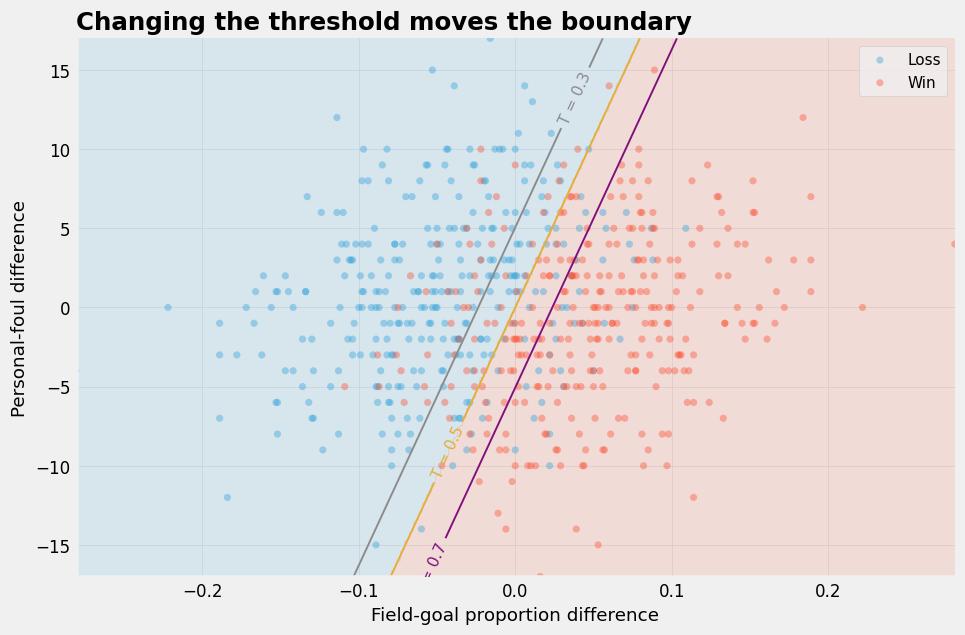

In [21]:
features = ['FG_PCT_DIFF', 'PF_DIFF']
two_feature_model = LogisticRegression(C=1e6, max_iter=2000)
two_feature_model.fit(train[features], train.WON)
utils.boundaries(two_feature_model, val[features], val.WON)

<p>The points are validation games. Shading shows the class at T = 0.5, and the thin contours show three thresholds. The model and its coefficients are unchanged across the contours.</p>

<p>Takeaway: A threshold picks a contour of equal predicted probability. A logistic model with a linear score gives a straight boundary in two-feature space. Next, extend classification from two outcomes to several mutually exclusive classes.</p>

<a id="section5"></a><h2>5. Multiclass Classification</h2><p>Question: How do we extend the decision to more than two classes?</p>

<h3>5.1 One classifier per class</h3><p>Iris has three mutually exclusive flower species. One-vs-rest fits one binary classifier for each species against the other two. We use petal measurements so the decision regions can be shown in two dimensions.</p><p><code>OneVsRestClassifier</code> handles the three binary fits. We call <code>fit</code>, <code>predict_proba</code> and <code>predict</code> with the same interface used for the NBA model.</p>

In [22]:
iris = load_iris(as_frame=True)
flower_X = iris.data[['petal length (cm)', 'petal width (cm)']]
flower_y = iris.target
flower_train, flower_val = train_test_split(np.arange(len(flower_y)),
    test_size=0.25, random_state=RANDOM_STATE, stratify=flower_y)
flower_model = OneVsRestClassifier(LogisticRegression(max_iter=2000))
flower_model.fit(flower_X.iloc[flower_train], flower_y.iloc[flower_train])

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegre...max_iter=2000)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=

<p>Inspect the first five validation flowers. Each probability column corresponds to one species. For this single-label task, <code>OneVsRestClassifier.predict_proba</code> normalizes the probabilities to sum to 1 across each row.</p>

In [23]:
flower_probability = flower_model.predict_proba(flower_X.iloc[flower_val])
display(pd.DataFrame(
    flower_probability, columns=iris.target_names[flower_model.classes_]
).head().round(3))

,setosa,versicolor,virginica
0,0.801,0.199,0.000
1,0.001,0.423,0.576
2,0.000,0.248,0.752
3,0.000,0.398,0.602
4,0.000,0.373,0.627


<p><code>classification_report</code> gives precision, recall and F1 for each species, treating each species in turn as the positive class. Support is the number of actual flowers of that species. The macro average gives each species equal weight. The weighted average weights each species by its support. Accuracy still counts the fraction of all flowers labelled correctly.</p>

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        13
  versicolor      1.000     0.769     0.870        13
   virginica      0.800     1.000     0.889        12

    accuracy                          0.921        38
   macro avg      0.933     0.923     0.919        38
weighted avg      0.937     0.921     0.920        38



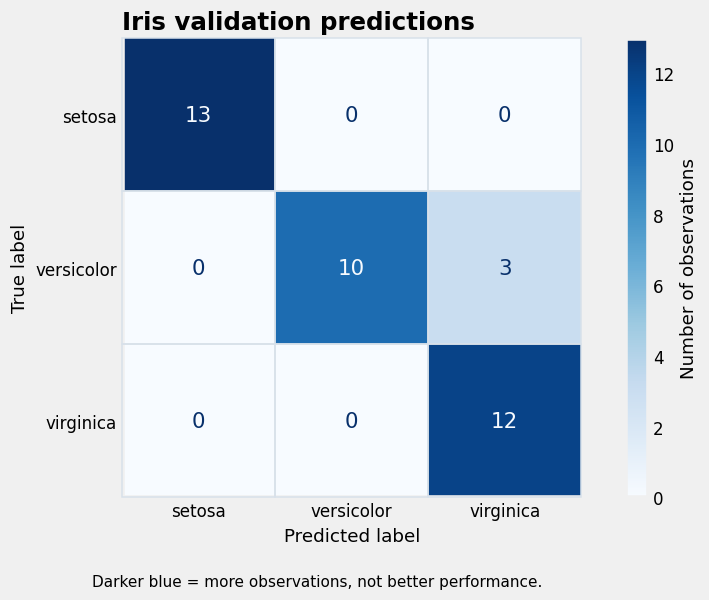

In [24]:
flower_prediction = flower_model.predict(flower_X.iloc[flower_val])
print(classification_report(
    flower_y.iloc[flower_val], flower_prediction,
    target_names=iris.target_names, digits=3, zero_division=0
))
utils.matrix(flower_y.iloc[flower_val], flower_prediction,
             'Iris validation predictions', labels=iris.target_names)

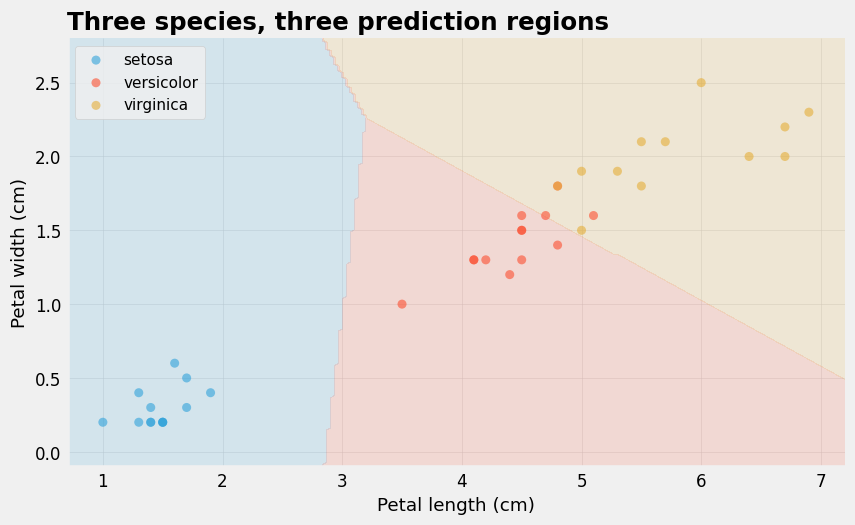

In [25]:
utils.iris_regions(flower_model, flower_X.iloc[flower_val],
                   flower_y.iloc[flower_val], iris.target_names)

<p>The largest class score determines the prediction. These regions show a single-label problem: each flower receives one species. A multilabel task instead permits several labels for one observation and requires a different decision rule.</p>

<h3>5.2 Fit a multiclass model directly</h3><p>For three mutually exclusive classes, <code>LogisticRegression</code> also supports a direct multiclass fit. The default model fits all classes together with a multinomial loss. This differs from fitting three separate one-vs-rest models. Both use the same scikit-learn interface and receive the same training and validation observations here.</p>

In [26]:
multiclass_model = LogisticRegression(max_iter=2000)
multiclass_model.fit(flower_X.iloc[flower_train], flower_y.iloc[flower_train])
multiclass_prediction = multiclass_model.predict(flower_X.iloc[flower_val])
print(classification_report(
    flower_y.iloc[flower_val], multiclass_prediction,
    target_names=iris.target_names, digits=3, zero_division=0
))

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        13
  versicolor      0.917     0.846     0.880        13
   virginica      0.846     0.917     0.880        12

    accuracy                          0.921        38
   macro avg      0.921     0.921     0.920        38
weighted avg      0.923     0.921     0.921        38



<p>Compare the per-species errors on these validation flowers before choosing an approach. A difference on this small set does not establish which approach performs better on future flowers. A final estimate would need separate observations after choosing the model.</p>

<p>Takeaway: Multiclass classification needs a rule for combining class scores. Evaluate on held-out observations and inspect which classes are confused.</p>

<a id="summary"></a><h2>Lecture summary</h2><ul><li>A probability becomes a decision only after choosing a threshold.</li><li>The confusion matrix distinguishes false alarms from missed positives.</li><li>Choose precision, recall or another metric from the practical decision.</li><li>Use validation data to choose thresholds; keep a final test separate.</li><li>A decision boundary and a confusion matrix describe different aspects of the same classifier.</li></ul>